# 04 · Extensión a 14 géneros y el experimento del rock en español (escenario C)

Se agregan reguetón y rock en español al escenario B. El rock en español se plantea como
experimento: rock ya es un género de GTZAN, así que la pregunta es si el modelo distingue el rock en
español del rock de GTZAN y, si lo hace, por qué. Los MFCC describen el timbre, no la letra ni el
idioma.

In [1]:
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from generos import figuras, resultados as res
from generos.config import ESCENARIOS, NOMBRES

figuras.aplicar_estilo()
pd.set_option("display.precision", 3)

from generos import proyeccion

corridas = res.cargar()
resumen = res.resumen(corridas)

## Resultado en prueba (media ± desviación entre 3 semillas)

In [2]:
t = resumen.copy()
t["Modelo"] = t["modelo"].map(res.MODELOS)
t["Géneros"] = t["escenario"].map(lambda e: len(ESCENARIOS[e]))
t["Por segmento (%)"] = [f"{res.pct(a)} ± {res.pct(b)}" for a, b in zip(t["segmento_media"], t["segmento_de"])]
t["Por canción (%)"] = [f"{res.pct(a)} ± {res.pct(b)}" for a, b in zip(t["cancion_media"], t["cancion_de"])]
t.set_index(["escenario", "Modelo"])[["Géneros", "Por segmento (%)", "Por canción (%)"]]

Géneros Por segmento (%) Por canción (%)
escenario Modelo                                             
A         Red densa       10       36,2 ± 0,8      38,5 ± 3,2
          LSTM            10       33,2 ± 1,8      35,9 ± 2,1
B         Red densa       12       33,5 ± 0,8      36,5 ± 0,6
          LSTM            12       30,8 ± 2,0      33,0 ± 1,6
C         Red densa       14       30,4 ± 1,2      33,5 ± 1,4
          LSTM            14       28,8 ± 3,7      32,5 ± 4,8

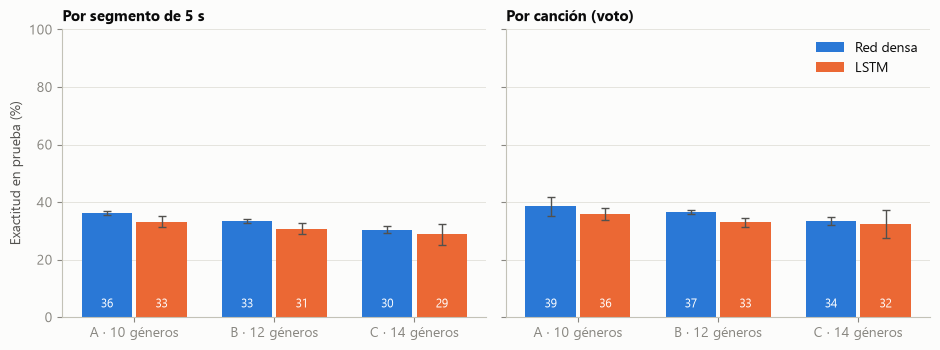

In [3]:
figuras.exactitud(resumen);

La exactitud por canción baja poco a poco al agregar géneros: de 38,5 a 33,5 % la densa y de 35,9 a
32,5 % la LSTM entre los escenarios A y C. En los tres escenarios la red densa queda igual o por
encima de la LSTM, con diferencias del orden de la variación entre semillas. Los conjuntos de prueba
crecen de un escenario a otro, así que la comparación entre escenarios es solo indicativa.

## Exactitud por género (escenario C)

In [4]:
sens = res.sensibilidad_por_genero("C")
(100 * sens).round(0).sort_values("LSTM", ascending=False)

,Red densa,LSTM
Clásica,96.0,92.0
Metal,96.0,72.0
Vallenato,58.0,62.0
Pop,59.0,59.0
Reguetón,31.0,47.0
Rock en español,43.0,38.0
Salsa,31.0,33.0
Reggae,28.0,22.0
Country,17.0,19.0
Jazz,9.0,14.0


## Rock y rock en español

In [5]:
r = res.rock_vs_rock_es("C")
r["modelo"] = r["modelo"].map(res.MODELOS)
r["real"] = r["real"].map(NOMBRES)
r.set_index(["modelo", "real"]).map(lambda v: f"{100 * v:.1f} %")

como_rock_es como_rock como_otro
modelo    real                                            
Red densa Rock en español       42.9 %     0.0 %    57.1 %
          Rock                  31.2 %     7.3 %    61.5 %
LSTM      Rock en español       38.1 %     0.0 %    61.9 %
          Rock                  24.0 %     7.3 %    68.8 %

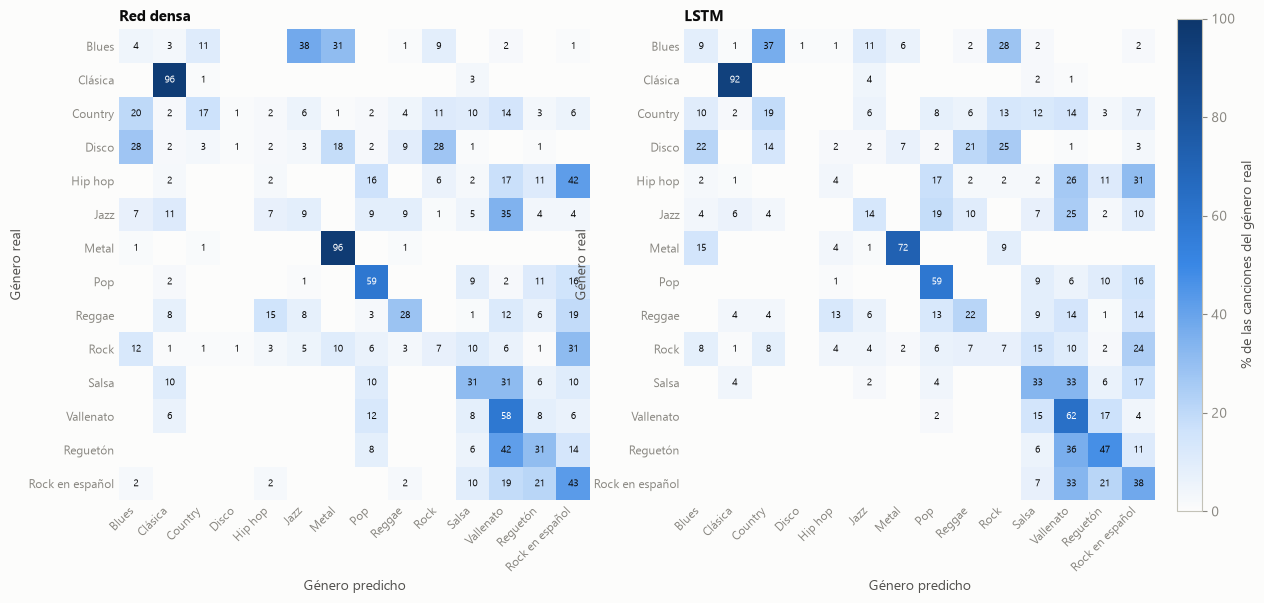

In [6]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 6.4))
for ax, m in zip(ejes, res.MODELOS):
    cm, generos = res.confusion_media("C", m)
    im = figuras.confusion(cm, generos, res.MODELOS[m], ax=ax)
fig.colorbar(im, ax=ejes, fraction=0.025, pad=0.02, label="% de las canciones del género real");

## ¿Género o fuente? (escenario C)

In [7]:
f = res.misma_fuente("C")
f["modelo"] = f["modelo"].map(res.MODELOS)
f.set_index(["modelo", "fuente"]).map(lambda v: f"{100 * v:.1f} %")

misma_fuente genero_correcto
modelo    fuente                              
Red densa GTZAN         71.7 %          32.0 %
          YouTube       85.6 %          41.4 %
LSTM      GTZAN         71.0 %          29.9 %
          YouTube       96.6 %          45.4 %

**Respuesta al experimento.** Los dos rocks no se separan como los separaría un oyente:

- **Rock en español → rock: nunca.** Con ambos modelos, el 0 % de las canciones de rock en español
  se predice como rock. Entre el 57 % y el 62 % se reparte entre otros géneros.
- **Rock de GTZAN → rock en español: con frecuencia.** Ocurre en el 31 % de los casos con la densa
  y en el 24 % con la LSTM, bastante más que los aciertos como rock (7 %).
- **La fuente pesa más que el género.** Las canciones de YouTube se predicen como un género de
  YouTube en el 86 % de los casos con la densa y en el 97 % con la LSTM.

El rock en español no se confunde con el rock de GTZAN en la dirección esperada. Se comporta como un
género más de la fuente YouTube, y la clase atrae además a una parte del rock de GTZAN. Con MFCC, que
describen timbre y no letra, el modelo no tiene cómo usar el idioma. Lo que separa es sobre todo el
origen de la grabación, y aun eso de forma imperfecta.

## Mapa de la representación aprendida

Cada punto es un segmento de prueba proyectado con t-SNE desde la penúltima capa de la LSTM del
escenario C (semilla 0). Cada panel resalta un género sobre el resto en gris.

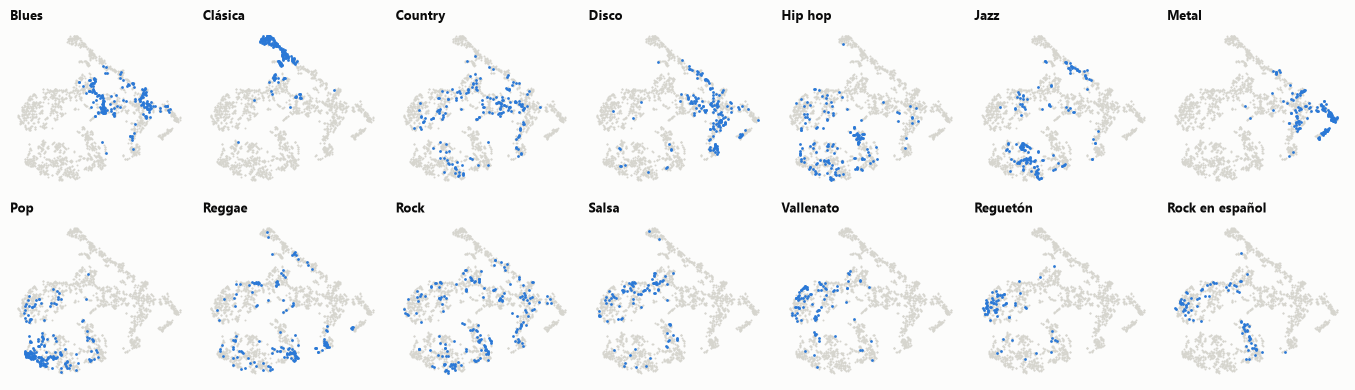

In [8]:
mapa = proyeccion.cargar("C", "lstm")
xy, generos = mapa[["x", "y"]].to_numpy(), mapa["genero"].to_numpy()
figuras.mapa_generos(xy, generos, list(ESCENARIOS["C"]));

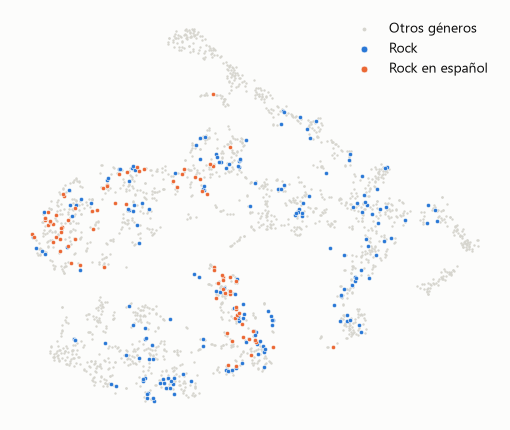

In [9]:
figuras.mapa_pareja(xy, generos, ("rock", "rock_es"));

In [10]:
vecinos = proyeccion.vecinos_mismo_genero(mapa).rename(index=NOMBRES)
print("Fracción de los 10 vecinos más cercanos en el mapa que son del mismo género:")
print((100 * vecinos).round(0).sort_values(ascending=False).to_string())
fuente = mapa["genero"].isin(["salsa", "vallenato", "reggaeton", "rock_es"]).map({True: "YouTube", False: "GTZAN"})
v_fuente = proyeccion.vecinos_mismo_genero(mapa.assign(genero=fuente))
base = fuente.value_counts(normalize=True)
print("\nAgrupando por fuente (vecinos de la misma fuente frente a la proporción de esa fuente en la prueba):")
for f_ in ("GTZAN", "YouTube"):
    print(f"  {f_}: {100 * v_fuente[f_]:.0f} % de vecinos de la misma fuente; proporción base {100 * base[f_]:.0f} %")

Fracción de los 10 vecinos más cercanos en el mapa que son del mismo género:
genero
Clásica            84.0
Metal              59.0
Blues              46.0
Pop                43.0
Jazz               37.0
Disco              34.0
Reggae             31.0
Vallenato          28.0
Reguetón           22.0
Hip hop            22.0
Country            20.0
Salsa              20.0
Rock en español    18.0
Rock               18.0

Agrupando por fuente (vecinos de la misma fuente frente a la proporción de esa fuente en la prueba):
  GTZAN: 91 % de vecinos de la misma fuente; proporción base 83 %
  YouTube: 55 % de vecinos de la misma fuente; proporción base 17 %


En el mapa solo la clásica forma una región compacta: el 84 % de los vecinos de un segmento de
clásica son de clásica. Le sigue el metal (59 %). Rock y rock en español son los menos agrupados
(18 % cada uno) y se mezclan entre sí y con el resto. Por fuente, en cambio, sí hay estructura: los
segmentos de YouTube tienen un 55 % de vecinos de YouTube, más del triple de su proporción en la
prueba (17 %).

## Conclusiones

1. **Con artistas distintos en entrenamiento y prueba, la LSTM no supera a la red densa.** En los
   tres escenarios la densa queda igual o por encima, y ninguna pasa del 40 % por canción con los
   10 géneros de GTZAN, aunque las dos superan con holgura el azar. Las dos memorizan el
   entrenamiento y generalizan poco a artistas nuevos.
2. **Los aciertos se concentran en géneros de timbre muy marcado** (clásica, metal, pop). Disco y
   rock casi nunca se reconocen.
3. **Los MFCC capturan la fuente tanto como el género.** Las canciones de YouTube que el modelo
   nunca vio se asignan a los géneros de YouTube que sí conoce, y el rock en español nunca se
   predice como rock. Con estos datos, género y fuente no se pueden separar del todo.
4. **Demo interactiva: no se construye.** Estaba condicionada a que el modelo generalizara a audio
   de otra fuente, y los resultados muestran lo contrario: un audio externo se clasificaría sobre
   todo por cómo fue grabado.

**Limitaciones**

- **Datos:** el conjunto es pequeño (442 canciones de entrenamiento de GTZAN y entre 62 y 72 por
  género nuevo), y la prueba de cada género nuevo tiene solo 12 a 16 canciones.
- **Representación:** son 13 MFCC por ventana, sin información de ritmo a largo plazo.
- **Etiquetas:** el género de las listas curadas no tiene una segunda revisión independiente.
- **Diseño:** para separar género y fuente harían falta los mismos géneros grabados desde varias
  fuentes, por ejemplo salsa y rock tanto de GTZAN como de YouTube.